# Evaluation and figures (RQ1-RQ4)

This notebook displays the outputs of `run.sh evaluate` (primary evaluation: coverage, binding yield, acceptance tests), `run.sh figures` and `run.sh analyze` (secondary analyses: hardness factors, capabilities, reconciliation, optimality gaps, HSC reference quality). It computes nothing itself.

* **RQ1 - What makes a QFBS instance hard?** `secondary/factor_analysis.csv`, `factor_effects.csv`, `figures/fig_rq1_hardness`.
* **RQ2 - Which instances can each solver process, and how often does it return a binding?** `evaluation/outcomes_by_suite_engine.csv`, `figures/rq2_engine_coverage`, `secondary/capability_matrix.csv`, `incompatibilities.csv`, `termination_reasons.csv`.
* **RQ3 - How do outcomes differ between the QFBS feasibility settings, and do the solvers' verdicts agree per instance?** `evaluation/qfbs_outcomes.csv`, `secondary/reconciliation_summary.csv`, `contradictions.csv`, `figures/fig_rq3_reconciliation`.
* **RQ4 - How close are heuristic bindings to certified optima (and to the authors' reference compositions in HSC)?** `secondary/optimality_gap.csv`, `vs_cp_incumbent.csv`, `hsc_quality_summary.json`, `figures/fig_rq4_gap`, `fig_rq4_gap_recovered`, `fig_rq4_hsc`.


In [1]:
from pathlib import Path
import csv, json
import pandas as pd
from IPython.display import display, SVG, Markdown
ROOT = Path.cwd()
ART = ROOT / ".artifacts/qacobench"
EVAL, FIG, SEC = ART / "evaluation", ART / "figures", ART / "secondary"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

def show_svg(path):
    display(SVG(filename=str(path))) if Path(path).is_file() else print("missing", path)

def table(path, **kw):
    return pd.read_csv(path, **kw) if Path(path).is_file() else print("missing", path)


## Acceptance of the campaign

The evaluation accepts a campaign only when the release counts match, no run is duplicated, no infrastructure error occurred, no guaranteed-feasible instance is labelled UNSAT, and the exact labels survive reconciliation (`unsat_with_validated_binding = 0`, `optimal_beaten_by_other_engine = 0`).

In [2]:
print(json.dumps(json.loads((EVAL / "acceptance.json").read_text()), indent=2))
print(json.dumps(json.loads((EVAL / "reconciliation_failures.json").read_text()), indent=2)[:2000])

{
  "duplicates": 0,
  "evaluation": "gateway outcomes and returned bindings (validated by the gateway); exact labels are reconciled against the heuristic engines' validated scores with a 1e-9 tolerance",
  "expected_runs": 46350,
  "guaranteed_group_unsat_responses": 0,
  "infrastructure_errors": 0,
  "ok": true,
  "optimal_beaten_by_other_engine": 0,
  "runs": 46350,
  "unique_triples": 46350,
  "unsat_with_validated_binding": 0
}
{
  "optimal_beaten_by_other_engine": [],
  "unsat_with_validated_binding": []
}


## RQ1 - What makes a QFBS instance hard?

Marginal outcome rates per design-factor level: share of instances the exact solver settles within 5 s (OPTIMAL or UNSAT), median proof time, unresolved instances, and the share of certified optima the GA attains. Factors are ordered by the spread of the proof rate across their levels.

,factor,levels,proof_rate_min,proof_rate_max,proof_rate_spread,hardest_level(proof),GA_attains_min,GA_attains_max,GA_attains_spread,hardest_level(GA),unresolved_max
0,structure,8,0.896250,1.000000,0.103750,sequence,0.567742,0.873984,0.306242,sequence,0.0
1,size,3,0.945625,1.000000,0.054375,48,0.444444,0.977692,0.533248,48,0.0
2,objective_count,3,0.946875,1.000000,0.053125,5,0.558407,0.899863,0.341456,5,0.0
3,constraint_count_mode,2,0.962222,1.000000,0.037778,exact,0.669072,0.852399,0.183326,exact,0.0
4,constraint_count,3,0.958000,0.989375,0.031375,3,0.657002,0.810640,0.153638,3,0.0
5,aggregation,3,0.959000,0.988125,0.029125,default,0.649780,0.791990,0.142211,cost_max,0.0
6,constraint_setting,2,0.967222,0.988750,0.021528,0,0.600000,0.777741,0.177741,1,0.0
7,qos_distribution,3,0.967000,0.979375,0.012375,uniform,0.650322,0.801682,0.151360,mixed,0.0
8,candidate_distribution,3,0.968750,0.978125,0.009375,uniform_3_8,0.679941,0.776224,0.096283,uniform_3_8,0.0


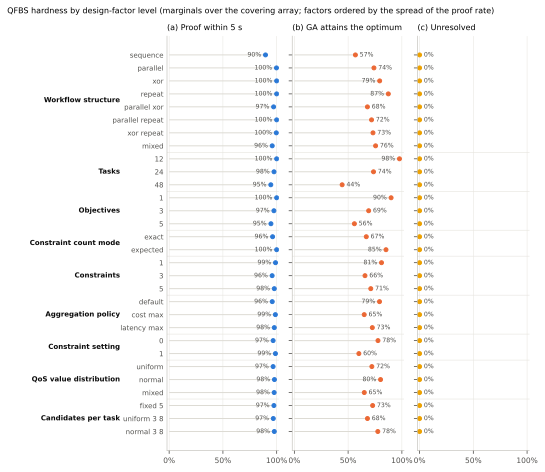

,factor,level,instances,MZN_proof_rate_all,MZN_median_proof_ms,unresolved_rate,GA_share_matches_optimum,GA_mean_gap_on_OPTIMAL
0,structure,sequence,800,0.896250,110.0,0.0,0.567742,0.013909
1,structure,parallel,600,0.998333,86.0,0.0,0.740175,0.007135
2,structure,xor,600,1.000000,92.0,0.0,0.793478,0.002857
3,structure,repeat,600,1.000000,85.0,0.0,0.873984,0.002666
4,structure,parallel_xor,600,0.971667,86.0,0.0,0.679558,0.008199
5,structure,parallel_repeat,600,1.000000,98.0,0.0,0.717949,0.008091
6,structure,xor_repeat,600,0.996667,79.0,0.0,0.731373,0.009768
7,structure,mixed,800,0.958750,82.0,0.0,0.755556,0.003711
8,candidate_distribution,fixed_5,2000,0.974500,88.0,0.0,0.728113,0.008417
9,candidate_distribution,uniform_3_8,1600,0.968750,99.0,0.0,0.679941,0.005920


In [3]:
display(table(SEC / "factor_effects.csv"))
show_svg(FIG.parent / "secondary/figures/fig_rq1_hardness.svg")
display(table(SEC / "factor_analysis.csv")[["factor", "level", "instances", "MZN_proof_rate_all", "MZN_median_proof_ms", "unresolved_rate", "GA_share_matches_optimum", "GA_mean_gap_on_OPTIMAL"]])

## RQ2 - Solver applicability: coverage and binding yield

Coverage = processable / submitted; conditional binding yield = binding returned / processable. Rejections are recorded as INCOMPATIBLE with the engine's own diagnostic, aggregated in the capability matrix; termination reasons separate proofs, evaluation budgets and the time budget.

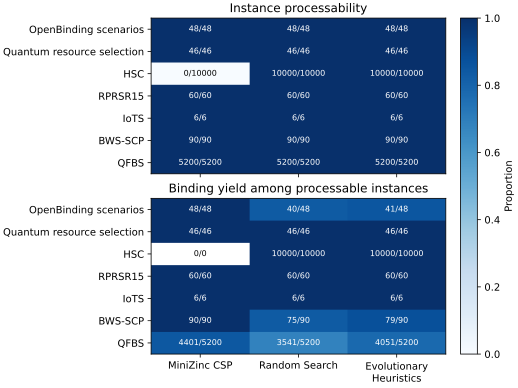

,suite,engine,submitted,processable,binding_returned,optimal,feasible,unsat,timeout,incompatible,error
0,01_icws,evolutionary-heuristics,48,48,41,0,41,0,7,0,0
1,01_icws,minizinc-csp,48,48,48,48,0,0,0,0,0
2,01_icws,random-search,48,48,40,0,40,0,8,0,0
3,02_quantum,evolutionary-heuristics,46,46,46,0,46,0,0,0,0
4,02_quantum,minizinc-csp,46,46,46,46,0,0,0,0,0
5,02_quantum,random-search,46,46,46,0,46,0,0,0,0
6,03_hsc_llm,evolutionary-heuristics,10000,10000,10000,0,10000,0,0,0,0
7,03_hsc_llm,minizinc-csp,10000,0,0,0,0,0,0,10000,0
8,03_hsc_llm,random-search,10000,10000,10000,0,10000,0,0,0,0
9,04_rprsr15,evolutionary-heuristics,60,60,60,0,60,0,0,0,0


,engine,reason,03_hsc_llm
0,minizinc-csp,aggregations: sequence.expression,10000
1,minizinc-csp,expressions: arithmetic,10000
2,minizinc-csp,expressions: call.product,8999
3,minizinc-csp,expressions: call.sum,9936
4,minizinc-csp,expressions: path.values,10000


,suite,engine,status,termination_reason,runs
0,01_icws,evolutionary-heuristics,FEASIBLE,evaluation_budget,41
1,01_icws,evolutionary-heuristics,TIMEOUT,evaluation_budget,7
2,01_icws,minizinc-csp,OPTIMAL,proof,48
3,01_icws,random-search,FEASIBLE,evaluation_budget,40
4,01_icws,random-search,TIMEOUT,evaluation_budget,8
5,02_quantum,evolutionary-heuristics,FEASIBLE,evaluation_budget,46
6,02_quantum,minizinc-csp,OPTIMAL,proof,46
7,02_quantum,random-search,FEASIBLE,evaluation_budget,46
8,03_hsc_llm,evolutionary-heuristics,FEASIBLE,evaluation_budget,9964
9,03_hsc_llm,evolutionary-heuristics,FEASIBLE,time_budget,36


In [4]:
show_svg(FIG / "rq2_engine_coverage.svg")
display(table(EVAL / "outcomes_by_suite_engine.csv"))
display(table(SEC / "capability_matrix.csv"))
display(table(EVAL / "termination_reasons.csv"))

## RQ3 - Outcomes under the two feasibility settings and cross-solver agreement

Per-instance reconciliation of the exact labels with the heuristics' gateway-validated bindings. `contradictions.csv` must be empty for the labels to be published.

,group,engine,runs,processable,binding_returned,timeout,unsat
0,guaranteed,evolutionary-heuristics,2600,2600,2600,0,0
1,guaranteed,minizinc-csp,2600,2600,2600,0,0
2,guaranteed,random-search,2600,2600,2599,1,0
3,non_guaranteed,evolutionary-heuristics,2600,2600,1451,1149,0
4,non_guaranteed,minizinc-csp,2600,2600,1801,0,799
5,non_guaranteed,random-search,2600,2600,942,1658,0


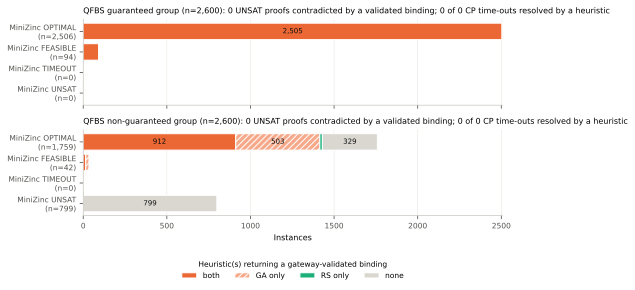

,subset,instances,MZN_OPTIMAL,MZN_FEASIBLE,MZN_UNSAT,MZN_TIMEOUT,MZN_INCOMPATIBLE,GA_binding,RS_binding,known_feasible(any engine),"unresolved(no engine binding, not UNSAT)",GA_miss_on_known_feasible,RS_miss_on_known_feasible,GA_binding_on_MZN_UNSAT,RS_binding_on_MZN_UNSAT,GA_binding_on_MZN_TIMEOUT,RS_binding_on_MZN_TIMEOUT,MZN_TIMEOUT_no_heuristic_binding,GA_better_than_MZN_OPTIMAL,RS_better_than_MZN_OPTIMAL
0,qfbs:guaranteed,2600,2506,94,0,0,0,2600,2599,2600,0,0,1,0,0,0,0,0,0,0
1,qfbs:non_guaranteed,2600,1759,42,799,0,0,1451,942,1801,0,350,859,0,0,0,0,0,0,0
2,qfbs:all,5200,4265,136,799,0,0,4051,3541,4401,0,350,860,0,0,0,0,0,0,0
3,01_icws,48,48,0,0,0,0,41,40,48,0,7,8,0,0,0,0,0,0,0
4,02_quantum,46,46,0,0,0,0,46,46,46,0,0,0,0,0,0,0,0,0,0
5,03_hsc_llm,10000,0,0,0,0,10000,10000,10000,10000,0,0,0,0,0,0,0,0,0,0
6,04_rprsr15,60,17,43,0,0,0,60,60,60,0,0,0,0,0,0,0,0,0,0
7,05_iots,6,6,0,0,0,0,6,6,6,0,0,0,0,0,0,0,0,0,0
8,06_bws_scp,90,19,71,0,0,0,79,75,90,0,11,15,0,0,0,0,0,0,0
9,corpus,15450,4401,250,799,0,10000,14283,13768,14651,0,368,883,0,0,0,0,0,0,0


,suite,instance_id,kind,engines,mzn_score,best_heuristic_score


In [5]:
display(table(EVAL / "qfbs_outcomes.csv"))
show_svg(FIG.parent / "secondary/figures/fig_rq3_reconciliation.svg")
display(table(SEC / "reconciliation_summary.csv"))
display(table(SEC / "contradictions.csv"))

## RQ4 - Solution quality against certified optima and reference compositions

Gap = heuristic score - MiniZinc optimum (same normalised weighted sum for every engine). For HSC, which has no exact proofs, the scores are compared with the authors' reference compositions (Eq. 1 + Eq. 2 recomputed on the released data).

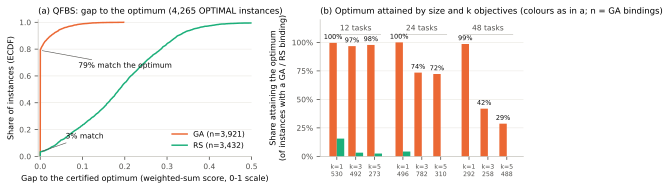

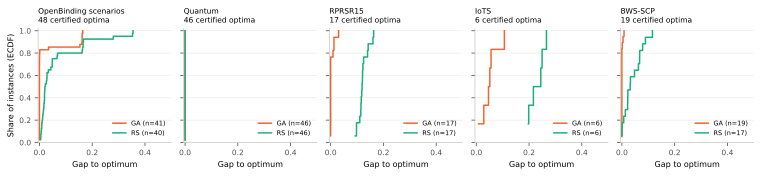

,by,level,engine,instances,with_binding,share_matches_optimum_of_bound,gap_mean,gap_p90,gap_max
0,qfbs,all,GA,4265,3921,0.791125,0.007103,0.025148,0.197437
1,qfbs,all,RS,4265,3432,0.033800,0.189025,0.325200,0.846481
2,group,guaranteed,GA,2506,2506,0.755786,0.008950,0.033988,0.197437
3,group,guaranteed,RS,2506,2505,0.032335,0.189985,0.325217,0.596741
4,group,non_guaranteed,GA,1759,1415,0.853710,0.003830,0.008999,0.163901
5,group,non_guaranteed,RS,1759,927,0.037756,0.186430,0.324824,0.846481
6,objective_count,1,GA,1458,1318,0.995448,0.000017,0.000000,0.009296
7,objective_count,1,RS,1458,1208,0.078642,0.192880,0.322048,0.846481
8,objective_count,3,GA,1677,1532,0.756527,0.009126,0.033335,0.197437
9,objective_count,3,RS,1677,1279,0.011728,0.176981,0.316643,0.543960


,subset,engine,MZN_FEASIBLE_instances,heuristic_with_binding,heuristic_better(<-1e-9),equal,heuristic_worse(>1e-9),median_diff,mean_diff,median_improvement_when_better
0,qfbs:guaranteed,GA,94,94,52,5,37,-0.002094,-0.041408,0.082137
1,qfbs:guaranteed,RS,94,94,3,0,91,0.206126,0.200672,0.026622
2,qfbs:non_guaranteed,GA,42,36,21,4,11,-0.006897,-0.052015,0.089357
3,qfbs:non_guaranteed,RS,42,15,2,0,13,0.148222,0.133064,0.078717
4,qfbs:all,GA,136,130,73,9,48,-0.002182,-0.044345,0.082967
5,qfbs:all,RS,136,109,5,0,104,0.195459,0.191368,0.032228
6,04_rprsr15,GA,43,43,28,1,14,-0.007084,-0.008088,0.019238
7,04_rprsr15,RS,43,43,0,0,43,0.146991,0.143163,NaN
8,06_bws_scp,GA,71,60,20,2,38,0.062494,0.064594,0.005013
9,06_bws_scp,RS,71,58,0,0,58,0.123567,0.112526,NaN


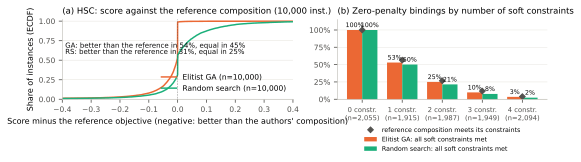

{
 "instances": 10000,
 "tasks: min/median/max": [
  1,
  3.0,
  21
 ],
 "levels: min/median/max": [
  1,
  2.0,
  10
 ],
 "instances with a parallel level": 7557,
 "candidates per task: min/median/max": [
  1,
  85.0,
  1187
 ],
 "log10 |B|: min/median/max": [
  0.0,
  4.00518051250378,
  46.18538976382306
 ],
 "constraints: distribution": {
  "0": 2055,
  "1": 1915,
  "2": 1987,
  "3": 1949,
  "4": 2094
 },
 "objectives: distribution": {
  "2": 3323,
  "3": 3388,
  "4": 3289
 },
 "reference binding complete": 10000,
 "reference violates its own soft constraints (penalty > 0)": 6023,
 "reference median penalty when violated": 0.11522299414617306,
 "corr(authors' best_value, recomputed reference objective)": 0.7746023352134781,
 "max |best_value - recomputed reference objective|": 1.290436976688114,
 "share |best_value - recomputed| <= 1e-6": 0.0433,
 "GA: runs": 10000,
 "GA: INCOMPATIBLE": 0,
 "GA: binding yield": 1.0,
 "GA: instances with binding and reference": 10000,
 "GA: zero-pen

,n_constraints,instances,ref_violates_constraints,GA_binding,GA_zero_penalty,GA_better_than_ref,GA_equal_ref,GA_worse_than_ref,GA_median_gap,RS_binding,RS_zero_penalty,RS_better_than_ref,RS_equal_ref,RS_worse_than_ref,RS_median_gap
0,0,2055,0,2055,2055,1165,861,29,-0.004042,2055,2055,774,477,804,0.000000e+00
1,1,1915,834,1915,1016,1075,822,18,-0.003782,1915,960,694,443,778,0.000000e+00
2,2,1987,1457,1987,497,1055,909,23,-0.001228,1987,426,614,512,861,0.000000e+00
3,3,1949,1719,1949,193,1008,907,34,-0.001007,1949,151,540,499,910,0.000000e+00
4,4,2094,2013,2094,72,1095,972,27,-0.001154,2094,49,526,542,1026,1.110223e-16


In [6]:
show_svg(FIG.parent / "secondary/figures/fig_rq4_gap.svg")
show_svg(FIG.parent / "secondary/figures/fig_rq4_gap_recovered.svg")
g = table(SEC / "optimality_gap.csv")
display(g[["by", "level", "engine", "instances", "with_binding", "share_matches_optimum_of_bound", "gap_mean", "gap_p90", "gap_max"]])
display(table(SEC / "vs_cp_incumbent.csv"))
show_svg(FIG.parent / "secondary/figures/fig_rq4_hsc.svg")
print(json.dumps(json.loads((SEC / "hsc_quality_summary.json").read_text()), indent=1)[:3000])
display(table(SEC / "hsc_quality_by_constraints.csv"))

## Timing and budgets

Runtimes, termination reasons and time to the first feasible binding, per suite and engine.

,suite,engine,processed,share_proof,share_evaluation_budget,share_time_budget,share_engine_stop,runs_runtime>=4900ms,share_runtime>=4900ms,evaluations_mode,runtime_median_ms,runtime_p90_ms,no_binding_runs,no_binding_runtime_median_ms,first_feasible_median_ms,first_feasible_p90_ms,first_feasible_median_eval,best_median_ms,best_median_eval,overhead_median_ms
0,01_icws,GA,48,0.000000,1.000000,0.000000,0.0,0,0.000000,10000.0,1067.0,2663.2,7,2602.0,0.0,11.0,1.0,291.0,2743.0,1116.0485
1,01_icws,MZN,48,1.000000,0.000000,0.000000,0.0,0,0.000000,NaN,81.0,120.1,0,NaN,NaN,NaN,NaN,NaN,NaN,1038.7185
2,01_icws,RS,48,0.000000,1.000000,0.000000,0.0,0,0.000000,1000.0,91.0,326.6,8,235.5,0.0,2.3,1.0,43.0,555.0,1034.0365
3,02_quantum,GA,46,0.000000,1.000000,0.000000,0.0,0,0.000000,10000.0,140.0,203.0,0,NaN,0.0,0.0,1.0,0.0,3.0,936.8620
4,02_quantum,MZN,46,1.000000,0.000000,0.000000,0.0,0,0.000000,NaN,65.0,67.0,0,NaN,NaN,NaN,NaN,NaN,NaN,1010.9800
5,02_quantum,RS,46,0.000000,1.000000,0.000000,0.0,0,0.000000,1000.0,11.0,19.0,0,NaN,0.0,0.0,1.0,0.0,12.5,1062.6960
6,03_hsc_llm,GA,10000,0.000000,0.996400,0.003600,0.0,38,0.003800,10000.0,623.0,1501.0,0,NaN,0.0,0.0,1.0,40.0,594.0,924.9425
7,03_hsc_llm,RS,10000,0.000000,1.000000,0.000000,0.0,0,0.000000,1000.0,62.0,171.0,0,NaN,0.0,0.0,1.0,21.0,312.0,1072.0885
8,04_rprsr15,GA,60,0.000000,0.300000,0.700000,0.0,42,0.700000,10000.0,5000.0,5001.0,0,NaN,0.0,1.0,1.0,4834.5,4884.5,1412.5625
9,04_rprsr15,MZN,60,0.283333,0.000000,0.716667,0.0,43,0.716667,NaN,5027.0,5038.1,0,NaN,NaN,NaN,NaN,NaN,NaN,1380.2060


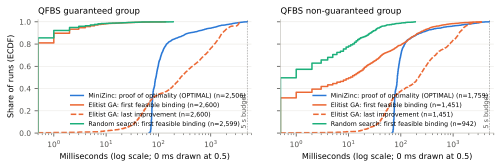

In [7]:
display(table(SEC / "timing_budget.csv"))
show_svg(FIG.parent / "secondary/figures/fig_time_to_binding.svg")
if (SEC / "repeat_variability.csv").is_file():
    display(table(SEC / "repeat_variability.csv"))